In [3]:
from pathlib import Path
import torch
from ultralytics import YOLO

print("CUDA available:", torch.cuda.is_available())

YOLO_PATH = Path("../data/yolo")

best_yolo = YOLO(
    "../models/yolo_runs/yolov8n_mri/weights/best.pt"
)

print("YOLO ready!")

CUDA available: True
YOLO ready!


In [5]:
##Evaluate YOLOv8

metrics = best_yolo.val(
    data=str((YOLO_PATH / "data.yaml").resolve()),
    device=0,
    workers=0,
    batch=1,
    imgsz=512,
    plots=False
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.184 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX 2000 Ada Generation Laptop GPU, 8188MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 892.0±439.0 MB/s, size: 23.7 KB)
val: Scanning /app/data/yolo/labels/val.cache... 512 images, 101 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 512/512 76.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 512/512 28.4it/s 18.1s0.0ss
                   all        512        456      0.938      0.915      0.958      0.762
                Glioma        135        165      0.916      0.854      0.923      0.716
            Meningioma        140        148      0.975      0.966      0.992      0.823
             Pituitary        136        143      0.923      0.923       0.96      0.747
Speed: 3.1ms preprocess, 19.0ms inference, 0.0ms loss, 2.8ms postprocess per image
mAP50: 0.9581658


image 1/1 /app/notebooks/../data/yolo/images/val/Meningioma_Tr-me_1223.jpg: 512x512 1 Meningioma, 19.9ms
Speed: 4.3ms preprocess, 19.9ms inference, 8.2ms postprocess per image at shape (1, 3, 512, 512)


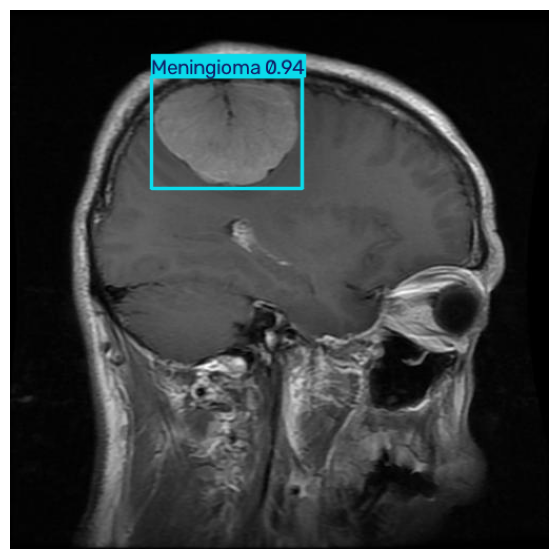

In [9]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

image_path = next(
    (YOLO_PATH / "images" / "val").glob("*.jpg")
)

predictions = best_yolo.predict(
    source=str(image_path),
    device=0,
    conf=0.25
)

plt.figure(figsize=(7, 7))

plt.imshow(
    predictions[0].plot()[:, :, ::-1]
)

plt.axis("off")
plt.show()

In [11]:
RESULTS_PATH = Path("../results")
RESULTS_PATH.mkdir(exist_ok=True)

yolo_results = pd.DataFrame({
    "Model": ["YOLOv8n"],
    "mAP50": [metrics.box.map50],
    "mAP50-95": [metrics.box.map]
})

yolo_results.to_csv(
    RESULTS_PATH / "yolo_evaluation.csv",
    index=False
)

print("YOLO results saved!")

YOLO results saved!
